# Figure S1a
Fixation location probability on twelve vertices with directed edges, for a mutant with $r=1.25$ at vertex $1$ (green). Gray vertices are impossible fixation locations.

In [1]:
import json

import matplotlib.pyplot as plt

from fixloc import style as S

d = json.load(open('data.json'))

In [2]:
PX = {
  3: (135, 118), 7: (530, 120), 9: (318, 213), 4: (715, 236), 5: (566, 354), 1: (867, 383), 6: (355, 401),
  8: (308, 535), 10: (576, 521), 2: (787, 567), 12: (425, 619), 11: (642, 707),
}
pos = {v: (x / 100.0, -y / 100.0) for v, (x, y) in PX.items()}
edges = [tuple(e) for e in d['edges']]
two = sorted({tuple(sorted(e)) for e in edges if (e[1], e[0]) in edges})
one = [e for e in edges if tuple(sorted(e)) not in two]
Pl = dict(zip(d['nodes'], d['P_last']))
fills = S.shade(S.CM_LAST, Pl, 0, 0.5)
for v in d['nodes']:
  if Pl[v] < 1e-12:
    fills[v] = S.LGRAY
fills[d['initial']] = S.ORIGIN

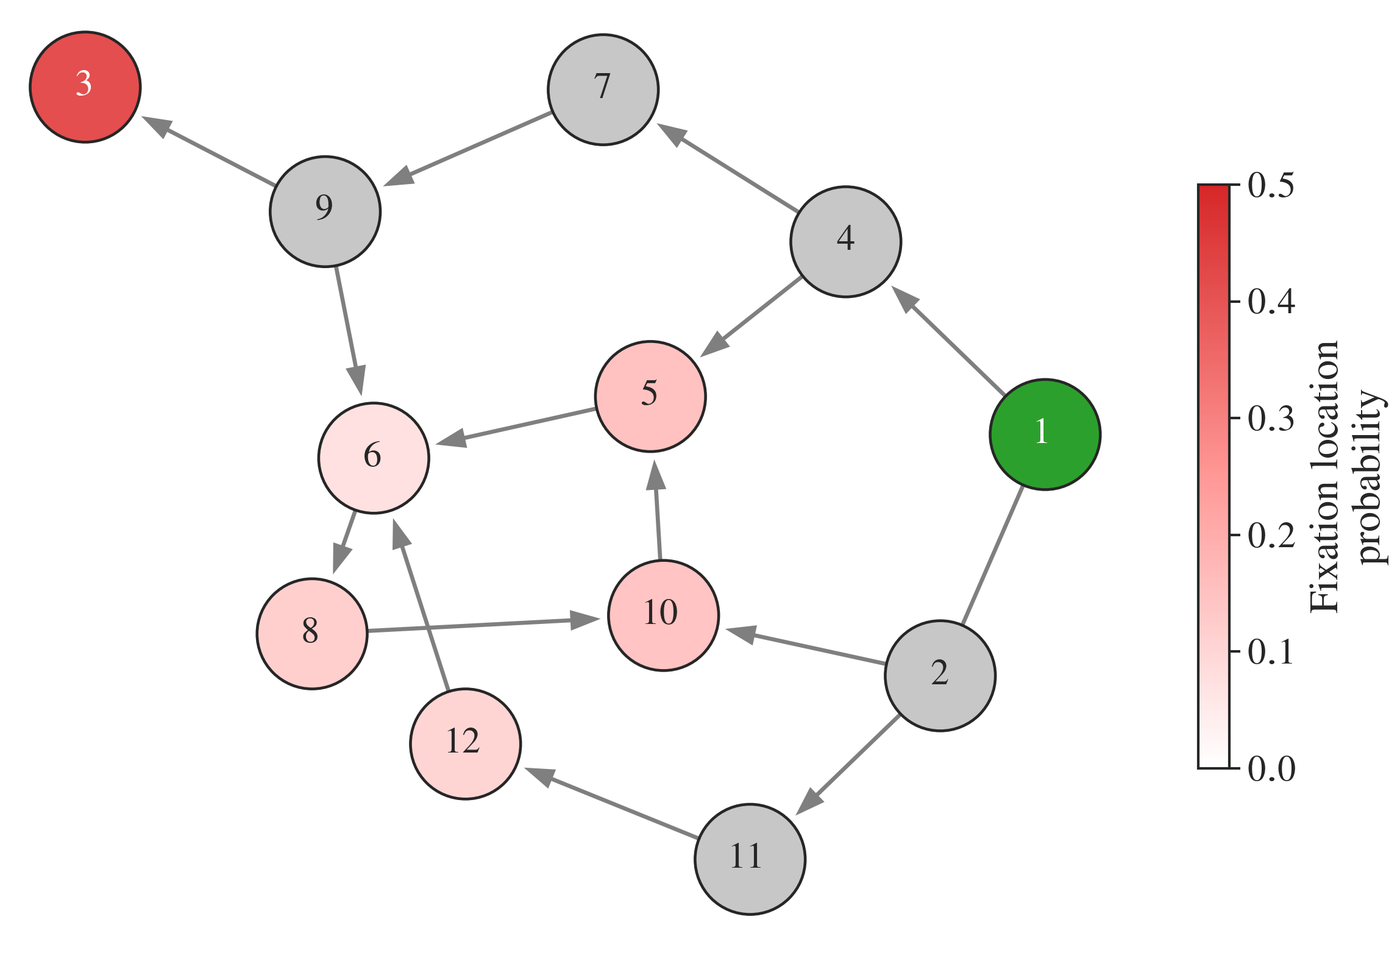

In [3]:
fig = plt.figure(figsize=(3.9, 2.85))
ax = fig.add_axes([0.0, 0.0, 0.8, 1.0])
S.draw_graph(ax, pos, two, fills, R=0.42, one_way=one, gap=0.06, link_lw=0.8)
for v in d['nodes']:
  dark = v == d['initial'] or Pl[v] / 0.5 > 1.6 / 3
  ax.text(*pos[v], r'$%d$' % v, ha='center', va='center', fontsize=7, color='white' if dark else S.INK, zorder=5)
ax.set_xlim(0.7, 9.4)
ax.set_ylim(-7.7, -0.6)
cax = fig.add_axes([0.84, 0.22, 0.022, 0.56])
S.colorbar(fig, cax, S.CM_LAST, 0, 0.5, [0, 0.1, 0.2, 0.3, 0.4, 0.5], 'Fixation location\nprobability')
S.save_panel(fig, 'a')